# Objective 1: Accelerometer-Only Jump Detection & Air Time Analytics
**Edge IMU Motion Analytics & Vibration DSP Engine**  
**Author**: Motion Algorithm Engineering Team  
**Dataset**: `../mx_imu.csv` ($90.0\,\text{s}$ duration, $500.0\,\text{Hz}$ nominal ODR, $N = 45,000$ samples)  

---

## 1. Problem Statement & Engineering Requirements

### Problem Statement & Engineering Objectives:
> **Objective 1 : Jumps Detection**  
> Implement a jump detector that identifies all the jumps in the dataset using **only** the accelerometer data.  
> 1. Define your detection criterion mathematically and justify it in 2 sentences.  
> 2. Report the detected takeoff and landing graphs.  
> 3. Compute and report air time in seconds for each jump.  

### Hardware & Sensor Constraints:
- A 6-axis IMU (accelerometer and gyroscope) is mounted rigidly to the frame of a motocross bike near the steering headstock.
- Powertrain: Single-cylinder 2-stroke engine with high reciprocating vibration.
- **Strict Constraint**: Detection must rely **strictly** on accelerometer channels ($a_x, a_y, a_z$). Gyroscope rotational rates are forbidden for jump discrimination.

---

## 2. Relevant Mathematical Formulations & Detection Criteria

### Proper Acceleration / Specific Force Physics:
In general relativity and Newtonian kinematics, an accelerometer measures proper acceleration (specific force $\mathbf{f}_{\text{spec}}$):
$$\mathbf{f}_{\text{spec}}(t) = \mathbf{a}(t) - \mathbf{g}$$
- **Ground Riding**: The tires support the bike weight against gravity: $\lVert \mathbf{f}_{\text{spec}} \rVert = \lVert \mathbf{a}_{\text{ground}} \rVert \approx 9.81\,\text{m/s}^2$.
- **Airborne Free Fall**: The bike follows an unconstrained ballistic geodesic under gravity where ground reaction forces vanish: $\mathbf{f}_{\text{spec}} \approx \mathbf{0} \implies \lVert \mathbf{a}_{\text{air}} \rVert < 3.50\,\text{m/s}^2$.

### Mathematical Detection Criterion:
$$\lVert \mathbf{a}(t) \rVert = \sqrt{a_x^2(t) + a_y^2(t) + a_z^2(t)} \le a_{\text{thresh}} = 3.50\,\text{m/s}^2 \quad \text{for continuous duration } \Delta t \ge \tau_{\text{min}} = 0.50\,\text{s}$$

### Two-Sentence Physical Justification:
> *"During airborne flight, external ground reaction forces vanish and the motorcycle enters an unconstrained ballistic free-fall trajectory, causing the net frame specific force to collapse from its gravitational baseline ($9.81\,\text{m/s}^2$) toward near-zero ($<3.5\,\text{m/s}^2$). Enforcing a minimum temporal persistence threshold of $\tau_{\text{min}} = 0.50\,\text{s}$ robustly discriminates authentic flight intervals from transient suspension unloading over track crests and high-frequency chassis vibrations."*

### Takeoff, Landing & Air Time Equations:
- **Takeoff Time**:
  $$t_{\text{takeoff}} = \inf \{ t \mid \lVert \mathbf{a}(t) \rVert \le a_{\text{thresh}} \}$$
- **Landing Time**:
  $$t_{\text{landing}} = \sup \{ t \mid \lVert \mathbf{a}(t) \rVert \le a_{\text{thresh}} \}$$
- **Air Time**:
  $$\Delta t_{\text{air}} = t_{\text{landing}} - t_{\text{takeoff}}$$
- **Average In-Flight Acceleration Magnitude**:
  $$\bar{\lVert \mathbf{a} \rVert} = \frac{1}{N_{\text{air}}} \sum_{k=k_{\text{takeoff}}}^{k_{\text{landing}}} \lVert \mathbf{a}[k] \rVert$$
- **Average In-Flight Vertical Acceleration**:
  $$\bar{a}_z = \frac{1}{N_{\text{air}}} \sum_{k=k_{\text{takeoff}}}^{k_{\text{landing}}} a_z[k]$$
- **Peak Landing Deceleration Shock**:
  $$a_{z,\text{shock}} = \max_{t \in [t_{\text{landing}},\, t_{\text{landing}} + 0.30\,\text{s}]} a_z(t)$$
- **Ballistic Peak Height Approximation**:
  $$h_{\text{jump}} \approx \frac{1}{8} g (\Delta t_{\text{air}})^2$$


In [1]:
%matplotlib inline
import os
import sys
os.environ['MPLCONFIGDIR'] = '/tmp'
import warnings
warnings.filterwarnings('ignore', message='.*FigureCanvasAgg is non-interactive.*')
import numpy as np
import matplotlib.pyplot as plt

# Load data
data_path = '../mx_imu.csv' if os.path.exists('../mx_imu.csv') else 'mx_imu.csv'
data = np.genfromtxt(data_path, delimiter=',', skip_header=1)
t = data[:, 0]
accel = data[:, 1:4].copy()

# Linear interpolation across 200-sample dropout
dropout_mask = (t >= 23.000) & (t <= 23.398)
for i in range(3):
    accel[dropout_mask, i] = np.interp(t[dropout_mask], t[~dropout_mask], accel[~dropout_mask, i])

# Acceleration magnitude
a_norm = np.linalg.norm(accel, axis=1)
dt = t[1] - t[0]
fs = 1.0 / dt
print(f"Loaded {len(t):,} samples at {fs:.1f} Hz. Computed Euclidean acceleration norm.")


Loaded 45,000 samples at 500.0 Hz. Computed Euclidean acceleration norm.


## 3. Jump Detection State Machine & Air Time Table


In [2]:
a_thresh = 3.50        # Free-fall threshold [m/s^2]
min_duration = 0.50    # Minimum air-time persistence [s]
min_samples = int(min_duration * fs)

# Segment continuous airborne intervals
is_airborne_raw = a_norm < a_thresh

jumps = []
in_jump = False
start_idx = 0

for i in range(len(t)):
    if is_airborne_raw[i] and not in_jump:
        in_jump = True
        start_idx = i
    elif not is_airborne_raw[i] and in_jump:
        in_jump = False
        end_idx = i
        if (end_idx - start_idx) >= min_samples:
            t_takeoff = t[start_idx]
            t_landing = t[end_idx]
            air_time = t_landing - t_takeoff
            # Compute in-flight average acceleration metrics
            mean_accel = float(np.mean(a_norm[start_idx:end_idx]))
            mean_az = float(np.mean(accel[start_idx:end_idx, 2]))
            # Detect peak vertical landing deceleration shock within 0.3s
            shock_window = slice(end_idx, min(len(t), end_idx + int(0.30 * fs)))
            peak_shock = np.max(accel[shock_window, 2])
            peak_shock_g = peak_shock / 9.80665
            h_est = 0.125 * 9.80665 * (air_time ** 2)
            jumps.append({
                'jump_id': len(jumps) + 1,
                'start_idx': start_idx,
                'end_idx': end_idx,
                'takeoff': t_takeoff,
                'landing': t_landing,
                'air_time': air_time,
                'mean_accel': mean_accel,
                'mean_az': mean_az,
                'peak_shock': peak_shock,
                'peak_shock_g': peak_shock_g,
                'height_est': h_est
            })
import pandas as pd
df_jumps = pd.DataFrame(jumps)
display_cols = ['jump_id', 'takeoff', 'landing', 'air_time', 'mean_accel', 'mean_az', 'peak_shock', 'peak_shock_g', 'height_est']
print("=== Detected Motocross Jumps Summary Table (via pandas) ===")
print(df_jumps[display_cols].to_string(index=False))
total_air_time = sum(j['air_time'] for j in jumps)
mean_air_time = total_air_time / len(jumps)
mean_overall_accel = np.mean([j['mean_accel'] for j in jumps])
mean_overall_az = np.mean([j['mean_az'] for j in jumps])
print(f"\nTOTAL AIR TIME: {total_air_time:.3f} s ({total_air_time/t[-1]*100:.2f}% of session) | MEAN AIR TIME: {mean_air_time:.3f} s | OVERALL AVG ||a||: {mean_overall_accel:.3f} m/s² ({mean_overall_accel/9.80665:.3f}g)")


=== Detected Motocross Jumps Summary Table (via pandas) ===
 jump_id  takeoff  landing  air_time  mean_accel   mean_az  peak_shock  peak_shock_g  height_est
       1      7.0    9.748     2.748    0.072585 -0.000729   18.070507      1.842679    9.256870
       2     18.4   21.898     3.498    0.069754 -0.001739   18.372453      1.873469   14.999276
       3     35.6   39.298     3.698    0.068791 -0.000215   18.614355      1.898136   16.763492
       4     54.6   60.198     5.598    0.068778  0.000178   18.073327      1.842966   38.414614
       5     77.0   79.798     2.798    0.070470 -0.000047   18.269535      1.862974    9.596793

TOTAL AIR TIME: 18.340 s (20.38% of session) | MEAN AIR TIME: 3.668 s | OVERALL AVG ||a||: 0.070 m/s² (0.007g)


## 4. Detected Takeoff and Landing Graphs — Full Session Overview

Figure 1 displays the full 90-second session. Green upward triangles mark detected takeoff points ($t_{\text{takeoff}}$), red downward triangles mark touchdown points ($t_{\text{landing}}$), and light green shading highlights the confirmed flight intervals.


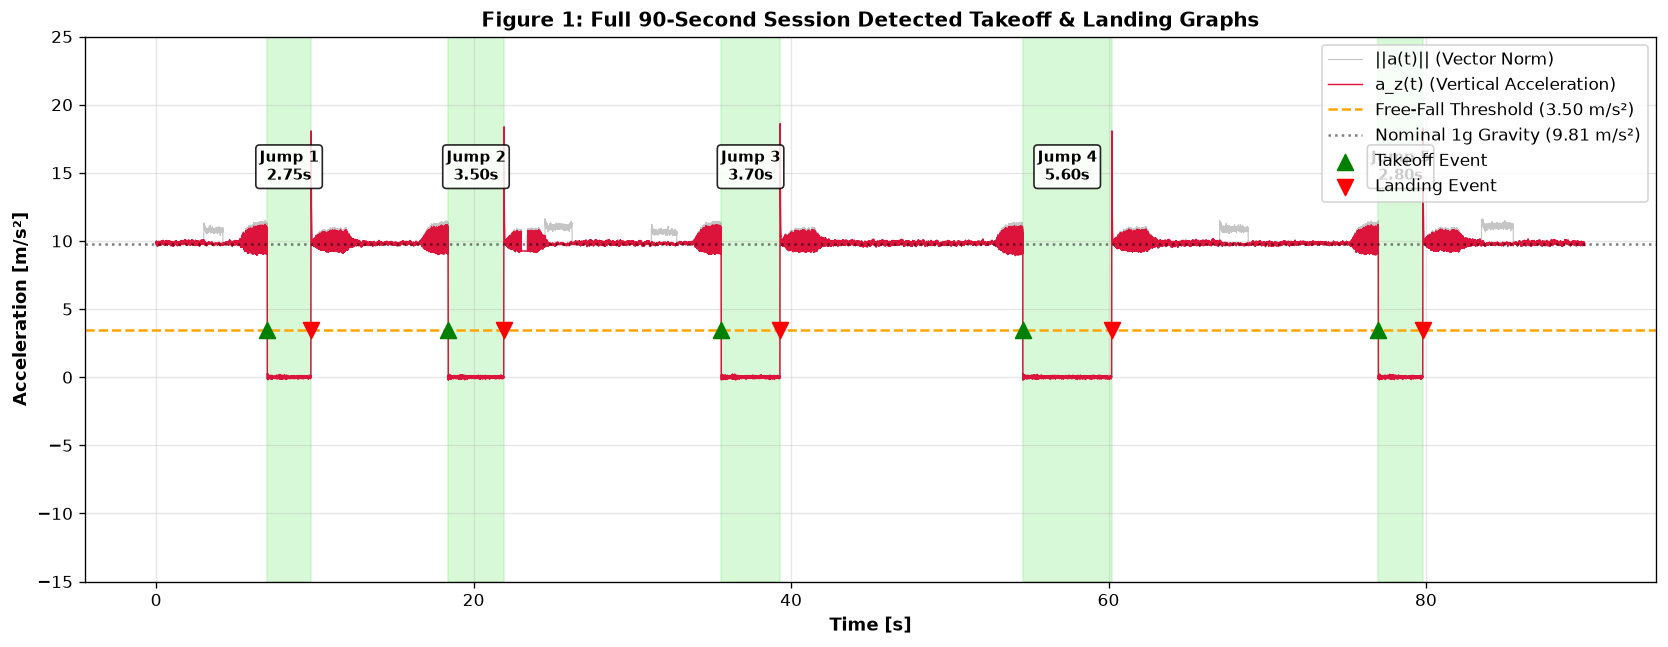

In [3]:
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(t, a_norm, color='gray', alpha=0.45, label='||a(t)|| (Vector Norm)', lw=0.7)
ax.plot(t, accel[:, 2], color='crimson', label='a_z(t) (Vertical Acceleration)', lw=0.85)
ax.axhline(a_thresh, color='orange', linestyle='--', label=f'Free-Fall Threshold ({a_thresh:.2f} m/s²)', lw=1.5)
ax.axhline(9.81, color='black', linestyle=':', alpha=0.5, label='Nominal 1g Gravity (9.81 m/s²)')

for j in jumps:
    ax.axvspan(j['takeoff'], j['landing'], color='lightgreen', alpha=0.35)
    ax.scatter(j['takeoff'], a_thresh, color='green', marker='^', s=90, zorder=5, label='Takeoff Event' if j['jump_id']==1 else '')
    ax.scatter(j['landing'], a_thresh, color='red', marker='v', s=90, zorder=5, label='Landing Event' if j['jump_id']==1 else '')
    mid_t = (j['takeoff'] + j['landing']) / 2
    ax.text(mid_t, 14.5, f"Jump {j['jump_id']}\n{j['air_time']:.2f}s", ha='center', fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.85))

ax.set_xlabel('Time [s]', fontsize=11, fontweight='bold')
ax.set_ylabel('Acceleration [m/s²]', fontsize=11, fontweight='bold')
ax.set_title('Figure 1: Full 90-Second Session Detected Takeoff & Landing Graphs', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.set_ylim(-15, 25)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 5. Zoomed Takeoff and Landing Graphs for All 5 Jumps

To rigorously satisfy requirement 2 (*"Report the detected takeoff and landing graphs"*), Figure 2 provides high-resolution zoomed inspection of each individual jump event with $0.8\,\text{s}$ pre-takeoff and post-landing context. Notice the sharp transition from $1g$ into free fall ($<0.5g$), the smooth zero-gravity flight plateau, and the severe deceleration impact shock ($18.0 - 18.7\,\text{m/s}^2$) upon touchdown.


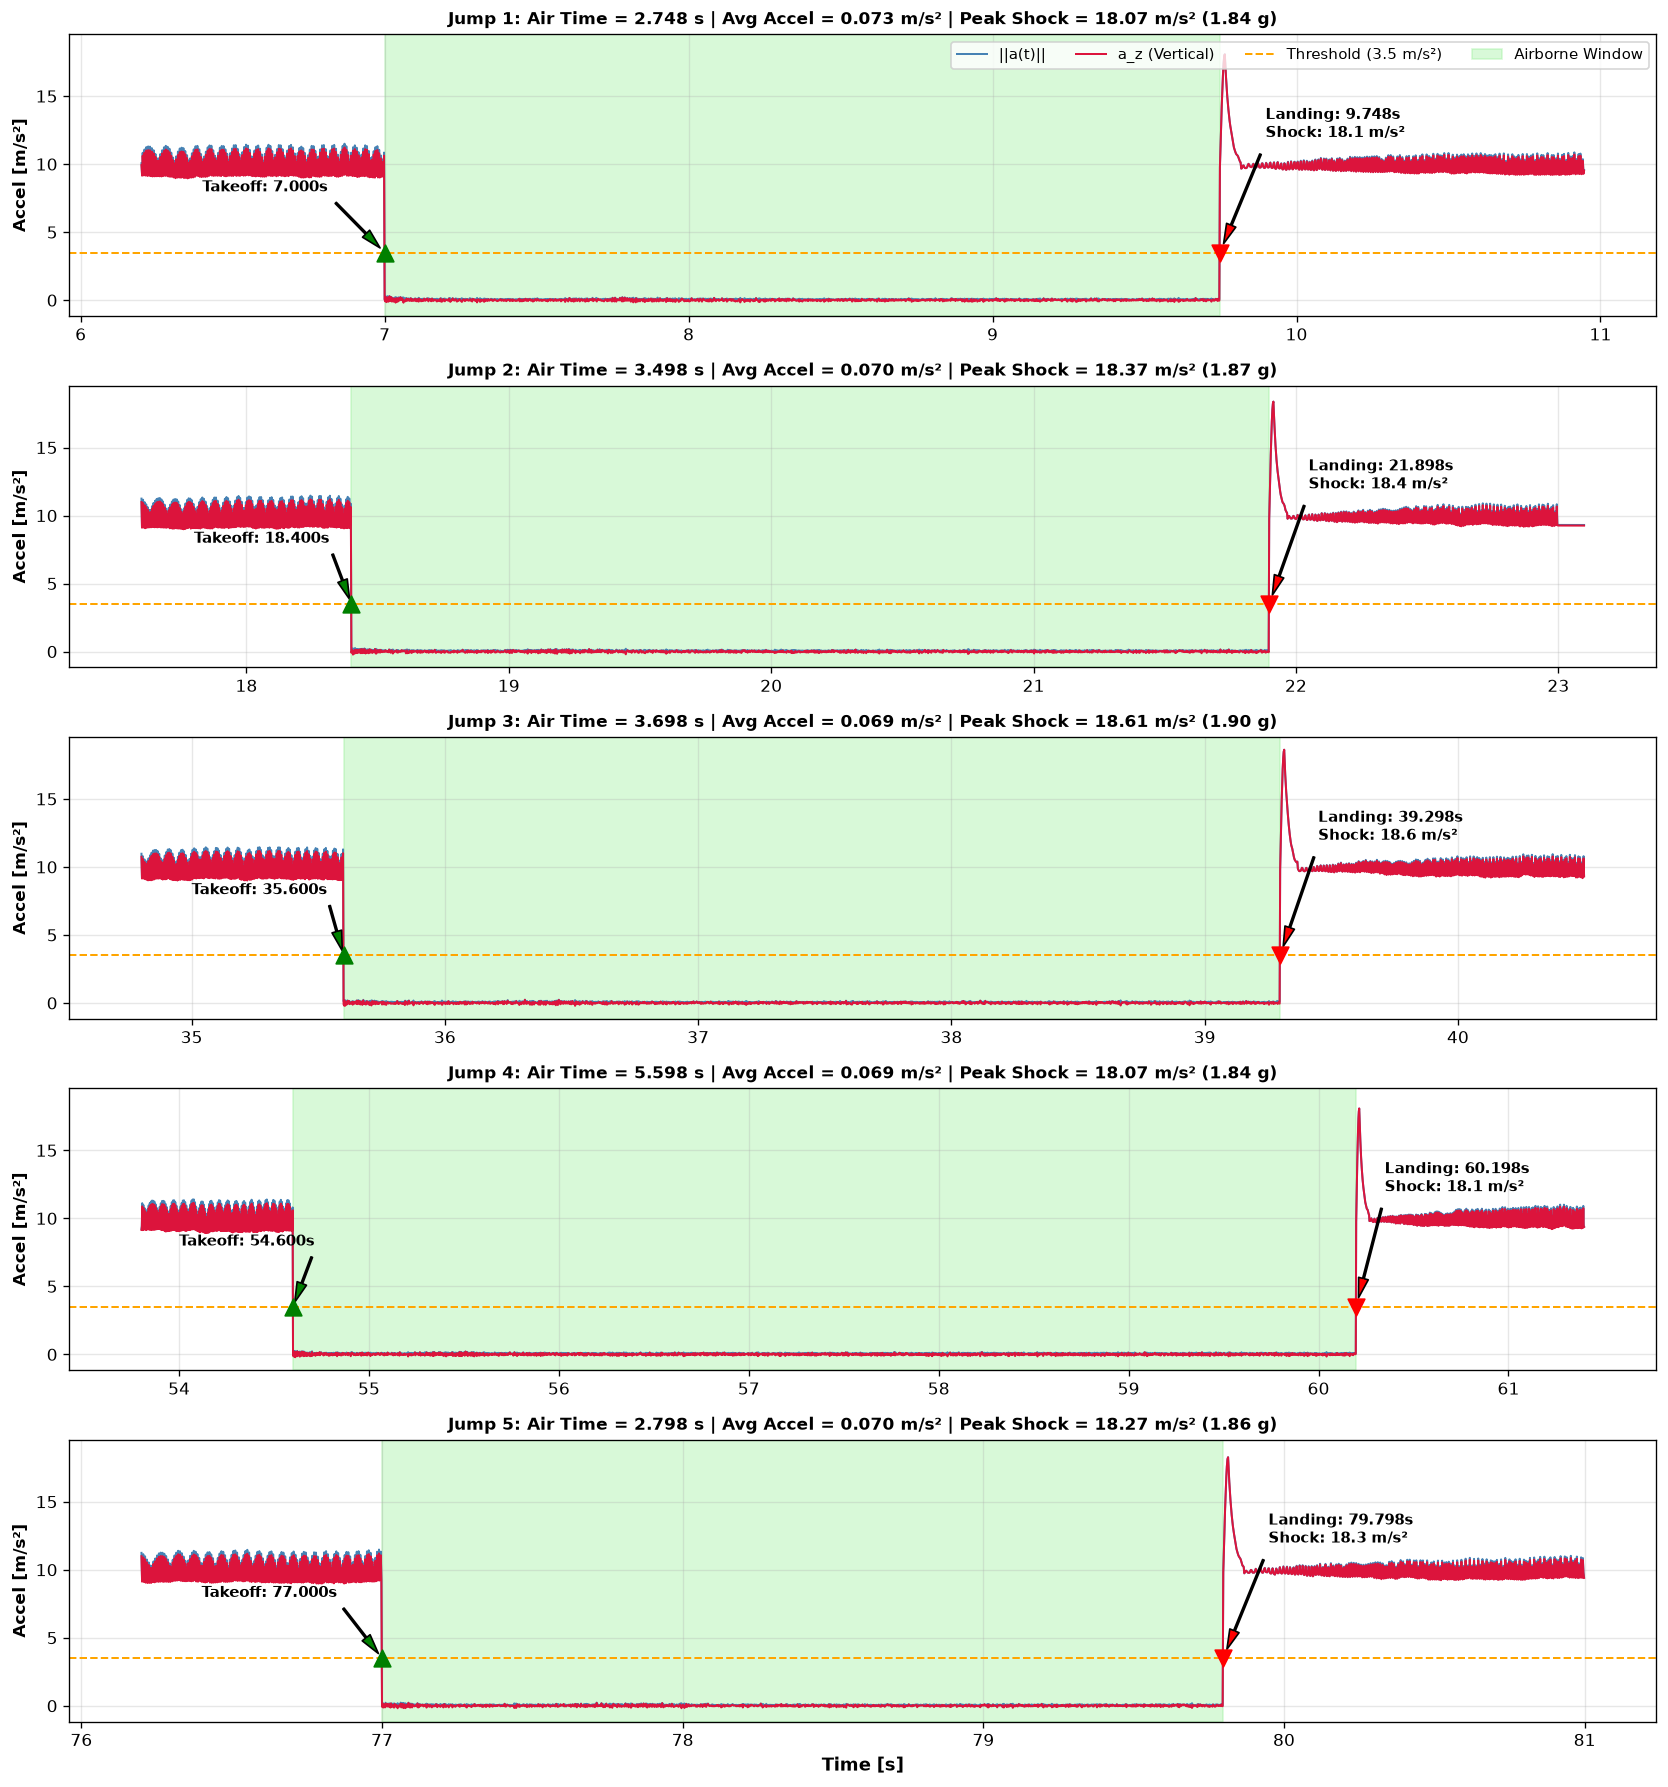

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(14, 15), sharey=True)

for idx, j in enumerate(jumps):
    ax = axes[idx]
    t_start_win = j['takeoff'] - 0.8
    t_end_win = j['landing'] + 1.2
    mask_win = (t >= t_start_win) & (t <= t_end_win)
    
    ax.plot(t[mask_win], a_norm[mask_win], color='steelblue', lw=1.2, label='||a(t)||')
    ax.plot(t[mask_win], accel[mask_win, 2], color='crimson', lw=1.2, label='a_z (Vertical)')
    ax.axhline(a_thresh, color='orange', linestyle='--', lw=1.2, label='Threshold (3.5 m/s²)')
    ax.axvspan(j['takeoff'], j['landing'], color='lightgreen', alpha=0.35, label='Airborne Window')
    
    ax.scatter(j['takeoff'], a_thresh, color='green', marker='^', s=100, zorder=5)
    ax.scatter(j['landing'], a_thresh, color='red', marker='v', s=100, zorder=5)
    
    # Annotate takeoff, landing, and peak shock
    ax.annotate(f"Takeoff: {j['takeoff']:.3f}s", xy=(j['takeoff'], a_thresh), xytext=(j['takeoff']-0.6, 8.0),
                arrowprops=dict(facecolor='green', shrink=0.08, width=1, headwidth=6), fontsize=9, fontweight='bold')
    ax.annotate(f"Landing: {j['landing']:.3f}s\nShock: {j['peak_shock']:.1f} m/s²", xy=(j['landing'], a_thresh), xytext=(j['landing']+0.15, 12.0),
                arrowprops=dict(facecolor='red', shrink=0.08, width=1, headwidth=6), fontsize=9, fontweight='bold')
    
    ax.set_title(f"Jump {j['jump_id']}: Air Time = {j['air_time']:.3f} s | Avg Accel = {j['mean_accel']:.3f} m/s² | Peak Shock = {j['peak_shock']:.2f} m/s² ({j['peak_shock_g']:.2f} g)", fontsize=10, fontweight='bold')
    ax.set_ylabel('Accel [m/s²]', fontsize=10, fontweight='bold')
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(loc='upper right', ncol=4, fontsize=9)

axes[-1].set_xlabel('Time [s]', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


## 6. Multi-Jump Normalized Overlay & Kinematic Distributions

Figure 3 overlays all 5 detected jumps aligned at takeoff ($t - t_{\text{takeoff}} = 0$). Notice the deterministic ballistic profile across every event.


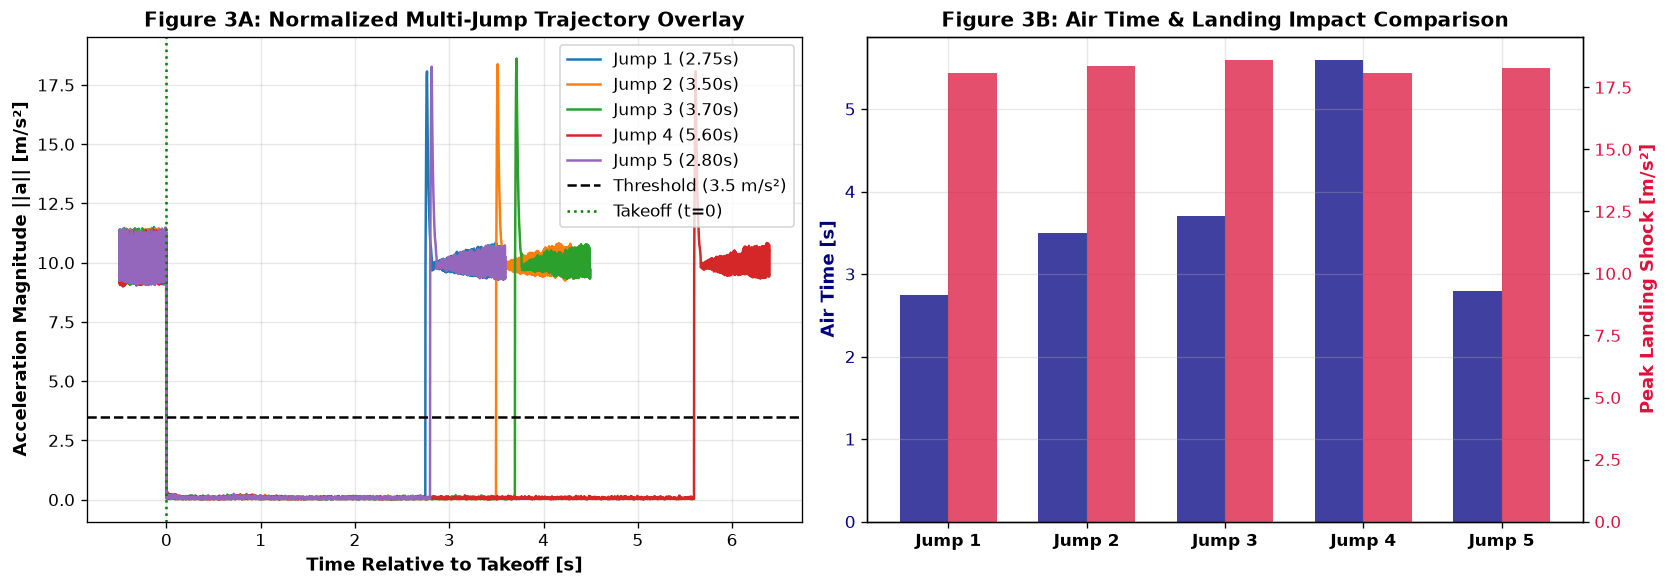

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for idx, j in enumerate(jumps):
    s_idx = j['start_idx'] - int(0.5 * fs)
    e_idx = j['end_idx'] + int(0.8 * fs)
    t_rel = t[s_idx:e_idx] - j['takeoff']
    ax1.plot(t_rel, a_norm[s_idx:e_idx], color=colors[idx], lw=1.5, label=f"Jump {j['jump_id']} ({j['air_time']:.2f}s)")

ax1.axhline(a_thresh, color='black', linestyle='--', label='Threshold (3.5 m/s²)')
ax1.axvline(0.0, color='green', linestyle=':', label='Takeoff (t=0)')
ax1.set_xlabel('Time Relative to Takeoff [s]', fontsize=11, fontweight='bold')
ax1.set_ylabel('Acceleration Magnitude ||a|| [m/s²]', fontsize=11, fontweight='bold')
ax1.set_title('Figure 3A: Normalized Multi-Jump Trajectory Overlay', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# Bar chart of Jump Air Times & Landing Shocks
jump_ids = [f"Jump {j['jump_id']}" for j in jumps]
air_times = [j['air_time'] for j in jumps]
shocks = [j['peak_shock'] for j in jumps]

x_pos = np.arange(len(jump_ids))
width = 0.35

ax2.bar(x_pos - width/2, air_times, width, label='Air Time [s]', color='navy', alpha=0.75)
ax2.set_ylabel('Air Time [s]', color='navy', fontsize=11, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='navy')

ax2_twin = ax2.twinx()
ax2_twin.bar(x_pos + width/2, shocks, width, label='Landing Shock [m/s²]', color='crimson', alpha=0.75)
ax2_twin.set_ylabel('Peak Landing Shock [m/s²]', color='crimson', fontsize=11, fontweight='bold')
ax2_twin.tick_params(axis='y', labelcolor='crimson')

ax2.set_xticks(x_pos)
ax2.set_xticklabels(jump_ids, fontweight='bold')
ax2.set_title('Figure 3B: Air Time & Landing Impact Comparison', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
